<a href="https://colab.research.google.com/github/costpetrides/Data_Analysis_Atmosphere/blob/main/Python_Slicing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import numpy as np
import matplotlib.pyplot as plt


# Mathematical Summations to Python Slicing

## 1. Indexing Rules

- Mathematics: $x_1$
- Python: `x[0]`
- `x[start:stop]`: `stop` is excluded.

---

## 2. Method 1 — NumPy Slicing

Consider the general summation:

$$
S=\sum_{i=a}^{b}x_{i+k}
$$

The slicing boundaries are:

$$
\boxed{
\text{start}=a+k-1,\qquad
\text{stop}=b+k
}
$$

```python
S = np.sum(x[a+k-1:b+k])
```

---

## 3. Method 2 — Explicit Indexing with np.arange()

Instead of calculating the slicing boundaries, we explicitly construct the Python indices corresponding to the summation limits.

For:

$$
S=\sum_{i=a}^{b}x_{i+k}
$$

we define:

$$
\boxed{
i=\texttt{np.arange(a-1,b)}
}
$$

Since the indices are already converted from mathematical indexing (1-based) to Python indexing (0-based), we can directly write:

$$
\boxed{
x_{i+k}\longrightarrow\texttt{x[i+k]}
}
$$

```python
i = np.arange(a-1, b)

S = np.sum(x[i+k])
```

---

## 4. Comparison of Both Methods

For the general summation:

$$
S=\sum_{i=a}^{b}x_{i+k}
$$

**Method 1 — NumPy Slicing**

```python
S = np.sum(x[a+k-1:b+k])
```

**Method 2 — Explicit Indexing**

```python
i = np.arange(a-1, b)

S = np.sum(x[i+k])
```

Both methods produce identical results when all indices are valid.

However, **NumPy slicing is generally more memory-efficient and often faster for large datasets**, since it typically creates a view rather than a copy. Explicit indexing is often easier to understand when dealing with complicated mathematical expressions (I know sorry hahaha)


### Exercise 1 — Mathematical Summations and NumPy Slicing

Consider the following data series:

\\[ x = [3,\ 5,\ 8,\ 12,\ 7,\ 10,\ 15,\ 6,\ 9,\ 4] \\]

Let \\(n=10\\) be the number of observations and \\(k=2\\) the lag.

Calculate the summation:

$$
S=\sum_{i=1}^{n-k} x_{i} x_{i+k}
$$

Restriction: Do not use loops.

In [9]:
x=np.array([3,5,8,12,7,10,15,6,9,4])
n=len(x)

k=2
x1=x[:n-k]
x2=x[k:n]
S=np.sum(x1*x2)
print(f"S = {S}")

S = 584


In [15]:
x=np.array([3,5,8,12,7,10,15,6,9,4])
n=len(x)

k=2
i = np.arange(0, n-k)
S=np.sum(x[i]*x[i+k])
print(f"S = {S}")

S = 584


## Exercise 2

Consider the data series:

$$
x=[3,5,8,12,7,10,15,6,9,4]
$$

Let $n=10$ and $k=2$.

Calculate:

$$
S=\sum_{i=1}^{n-k}(x_i-\bar{x}_{-})(x_{i+k}-\bar{x}_{+})
$$

where:

$$
\bar{x}_{-}=\frac{1}{n-k}\sum_{i=1}^{n-k}x_i
$$

$$
\bar{x}_{+}=\frac{1}{n-k}\sum_{i=1}^{n-k}x_{i+k}
$$

**Restriction:** Do not use `for` loops.

In [21]:
x = np.array([3,5,8,12,7,10,15,6,9,4])

n = len(x)
k = 2

x1 = x[:n-k]
x2 = x[k:n]

m1 = np.mean(x1)
m2 = np.mean(x2)

S = np.sum((x1-m1)*(x2-m2))

print(f"S = {S}")

S = -1.75


In [22]:
x = np.array([3,5,8,12,7,10,15,6,9,4])

n = len(x)
k = 2

i = np.arange(0, n-k)

m1 = np.mean(x[i])
m2 = np.mean(x[i+k])

S = np.sum((x[i]-m1)*(x[i+k]-m2))

print(f"S = {S}")


S = -1.75


## Exercise 3

Consider the data series:

$$
x=[3,5,8,12,7,10,15,6,9,4,11,14]
$$

Let $n=12$.

Calculate:

$$
S=\sum_{i=2}^{n-3}(x_{i+1}-x_{i-1})(x_{i+2}-x_i)
$$


**Restriction:** Do not use `for` loops.

In [17]:
x=np.array([3,5,8,12,7,10,15,6,9,4,11,14])
n=len(x)

x1=x[2:n-2]
x2=x[:n-4]
x3=x[3:n-1]
x4=x[1:n-3]
S=np.sum((x1-x2)*(x3-x4))
print(f"S= {S}")

S= 14


In [19]:
# Alternativly using i=linspace(a-1:b)
x=np.array([3,5,8,12,7,10,15,6,9,4,11,14])
n=len(x)
i = np.arange(1, n-3)

S = np.sum((x[i+1]-x[i-1])*(x[i+2]-x[i]))
print(f"S= {S}")

S= 14



## Exercise 4

Consider the data series:

$$
x=[4,7,2,9,12,5,8,15,6,11,3,10,14,7,13,5,9,16]
$$

Let:

$$
n=\operatorname{len}(x), \qquad k=3
$$

Calculate:

$$
\boxed{
S=
\sum_{i=2}^{n-k-2}
(x_{i+k}-x_{i-1})^2
+
\sum_{j=k+1}^{n-2}
(x_{j+1}-x_{j-k})(x_j-x_{j-1})
}
$$

**Restriction:** Do not use `for` loops **DO NOT MAKE Reindexing in this case... sorry!**


In [34]:

import numpy as np

x = np.array([4,7,2,9,12,5,8,15,6,11,3,10,14,7,13,5,9,16])

n = len(x)
k = 3

# First summation
x1 = x[k+1:n-2]
x2 = x[:n-k-3]

S1 = np.sum((x1-x2)**2)

# Second summation
x3 = x[k+1:n-1]
x4 = x[:n-k-2]
x5 = x[k:n-2]
x6 = x[k-1:n-3]

S2 = np.sum((x3-x4)*(x5-x6))

S = S1 + S2

print(f"S = {S}")


S = 392


In [32]:
x = np.array([4,7,2,9,12,5,8,15,6,11,3,10,14,7,13,5,9,16])
n = len(x)
k = 3

i = np.arange(1, n-k-2)
j = np.arange(k, n-2)

S = np.sum((x[i+k]-x[i-1])**2) + np.sum((x[j+1]-x[j-k])*(x[j]-x[j-1]))

print(f"S = {S}")

S = 392



## Exercise 5

Consider the following time series:

$$
x=[33,32,30,29,25,30,37,37,29,30,36,32,33,34,53,45,25,28,32,27,26,28,24,26,9,22,17,26,27,30,34]
$$

Let:

$$
n=\operatorname{len}(x)
$$

Calculate the autocorrelation coefficient:

$$
\boxed{
r_k=
\frac{
\displaystyle\sum_{i=1}^{n-k}
(x_i-\bar{x}_{-})(x_{i+k}-\bar{x}_{+})
}{
\sqrt{
\displaystyle\sum_{i=1}^{n-k}(x_i-\bar{x}_{-})^2
\displaystyle\sum_{i=k+1}^{n}(x_i-\bar{x}_{+})^2
}
}
}
$$

where:

$$
\bar{x}_{-}=\frac{1}{n-k}\sum_{i=1}^{n-k}x_i
$$

$$
\bar{x}_{+}=\frac{1}{n-k}\sum_{i=k+1}^{n}x_i
$$


Calculate the autocorrelation coefficients for $k=1,2,3,4,5$ and  plot the autocorrelation coefficient $r_k$ against lag $k$ for $k=1 \ldots,5$ using Matplotlib.

### Restrictions
- Do not use `np.corrcoef()`.


A handy trick to make summations share the same limits!

$$
\boxed{
\sum_{i=a}^{b} f(i)
=
\sum_{j=c}^{b-a+c} f(j+a-c)
}
$$

Let's tame that terrifying second sum in the denominator!

$$
\boxed{
\sum_{i=k+1}^{n}(x_i-\bar{x}_{+})^2
=
\sum_{i=1}^{n-k}(x_{i+k}-\bar{x}_{+})^2
}
$$

### But do we actually need this?

**For NumPy slicing:** Not really! We can obtain the correct slices directly by substituting the summation limits.

**For explicit indexing with `i = np.arange()`:** Reindexing can be very helpful because it allows different summations to share the same index array.

After reindexing:

```python
i = np.arange(0, n-k)

S = np.sum((x[i+k] - xp)**2)
``

Same maths, smarter indexing!


Lag      Autocorrelation
1        0.5188
2        0.2677
3        0.1979
4        0.2337
5        0.0842


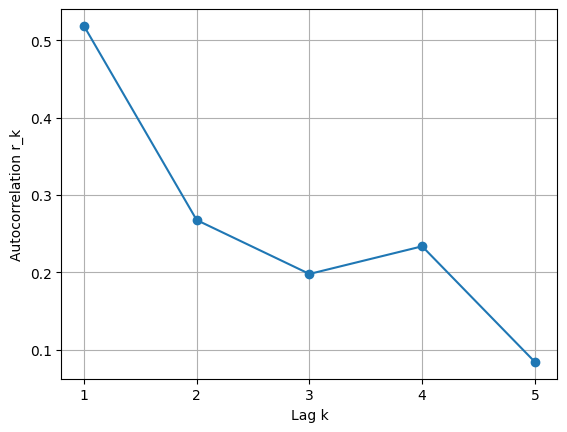

In [69]:

import numpy as np
import matplotlib.pyplot as plt

x = np.array([33,32,30,29,25,30,37,37,29,30,36,32,33,34,53,45,25,28,32,27,26,28,24,26,9,22,17,26,27,30,34])

n = len(x)
max_lag = 5
r = np.zeros(max_lag)

for k in range(1, max_lag+1):

    x1 = x[:n-k]
    x2 = x[k:]

    m1 = np.mean(x1)
    m2 = np.mean(x2)

    numerator = np.sum((x1-m1)*(x2-m2))

    denominator = np.sqrt(
        np.sum((x1-m1)**2) *
        np.sum((x2-m2)**2)
    )

    r[k-1] = numerator / denominator

print("Lag      Autocorrelation")
for k in range(1, max_lag+1):
    print(f"{k}        {r[k-1]:.4f}")

lags = np.arange(1, max_lag+1)

plt.plot(lags, r, 'o-', linewidth=1.5)
plt.xlabel("Lag k")
plt.ylabel("Autocorrelation r_k")
plt.xticks(lags)
plt.grid()
plt.show()


Lag      Autocorrelation
1        0.5198
2        0.2678
3        0.1985
4        0.2354
5        0.0885


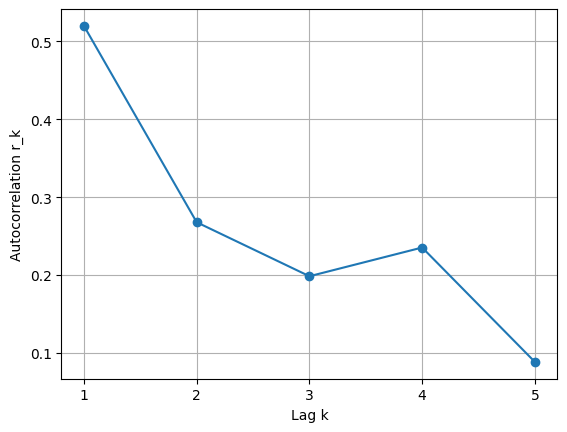

In [71]:

import numpy as np
import matplotlib.pyplot as plt

x = np.array([33,32,30,29,25,30,37,37,29,30,36,32,33,34,53,45,25,28,32,27,26,28,24,26,9,22,17,26,27,30,34])

n = len(x)
max_lag = 5
r = np.zeros(max_lag)

for k in range(1, max_lag+1):

    i = np.arange(0, n-k)

    m1 = np.mean(x[i])
    m2 = np.mean(x[j])

    numerator = np.sum((x[i]-m1)*(x[i+k]-m2))

    denominator = np.sqrt(
        np.sum((x[i]-m1)**2) *
        np.sum((x[i]-m2)**2)
    )

    r[k-1] = numerator / denominator

print("Lag      Autocorrelation")
for k in range(1, max_lag+1):
    print(f"{k}        {r[k-1]:.4f}")

lags = np.arange(1, max_lag+1)

plt.plot(lags, r, 'o-', linewidth=1.5)
plt.xlabel("Lag k")
plt.ylabel("Autocorrelation r_k")
plt.xticks(lags)
plt.grid()
plt.show()



## Exercise 6

Consider the following data series:

$$
x=[4,7,12,5,9,15,3,11,8,14,6,10,17,2,13,19,7,16,5,12,9,18,4,11,15]
$$

Let:

$$
n=\operatorname{len}(x),\qquad k=3
$$

Calculate:

$$
\boxed{
\begin{aligned}
S={}&
\sum_{i=2}^{n-k-3}
(x_{i+k}-x_{i-1})(x_{i+2}-x_i)\\[6pt]
&+\sum_{i=k+1}^{n-2}
(x_i-x_{i-k})^2\\[6pt]
&-\sum_{i=3}^{n-k}
(x_{i+k-1}-x_{i-2})(x_{i+1}-x_i)\\[6pt]
&+\sum_{i=k+2}^{n-1}
(x_i-x_{i-k-1})^2
\end{aligned}
}
$$

### Restrictions

- Do not use `for` or `while` loops.
- Do not manually calculate the individual terms.
- Use NumPy vectorised operations.




In [72]:

import numpy as np

x = np.array([4,7,12,5,9,15,3,11,8,14,6,10,17,2,13,19,7,16,5,12,9,18,4,11,15])

n = len(x)
k = 3

# First summation
S1 = np.sum(
    (x[k+1:n-3] - x[:n-k-4]) *
    (x[3:n-k-1] - x[1:n-k-3])
)

# Second summation
S2 = np.sum(
    (x[k:n-2] - x[:n-k-2])**2
)

# Third summation
S3 = np.sum(
    (x[k+1:n-1] - x[:n-k-2]) *
    (x[3:n-k+1] - x[2:n-k])
)

# Fourth summation
S4 = np.sum(
    (x[k+1:n-1] - x[:n-k-2])**2
)

S = S1 + S2 - S3 + S4

print(f"S = {S}")


S = 1534


In [73]:

import numpy as np

x = np.array([4,7,12,5,9,15,3,11,8,14,6,10,17,2,13,19,7,16,5,12,9,18,4,11,15])

n = len(x)
k = 3

# First summation
i = np.arange(1, n-k-3)

S1 = np.sum(
    (x[i+k] - x[i-1]) *
    (x[i+2] - x[i])
)

# Second summation
j = np.arange(k, n-2)

S2 = np.sum(
    (x[j] - x[j-k])**2
)

# Third summation
l = np.arange(2, n-k)

S3 = np.sum(
    (x[l+k-1] - x[l-2]) *
    (x[l+1] - x[l])
)

# Fourth summation
m = np.arange(k+1, n-1)

S4 = np.sum(
    (x[m] - x[m-k-1])**2
)

S = S1 + S2 - S3 + S4

print(f"S = {S}")


S = 1534
